In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report
from sklearn.inspection import permutation_importance, PartialDependenceDisplay

In [5]:
flights = pd.read_csv("ord_departures.csv")
weather = pd.read_csv("ord_weather.csv")

#parses specified column to be a datetime type
flights["scheduled_departure"] = pd.to_datetime(flights["scheduled_departure"])
weather["datetime"] = pd.to_datetime(weather["datetime"])

# rounds scheduled_departure to nearest hour and stores in new hour column
flights["hour"] = flights["scheduled_departure"].round('h')

#merge flights and weather into single dataframe and match rows where hour equals datetime
merged = pd.merge(flights, weather, left_on= "hour", right_on = "datetime")

len(flights), len(merged), len(flights) - len(merged)

(280052, 27348, 252704)

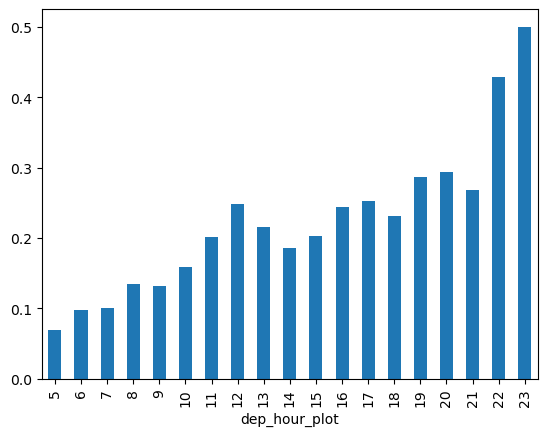

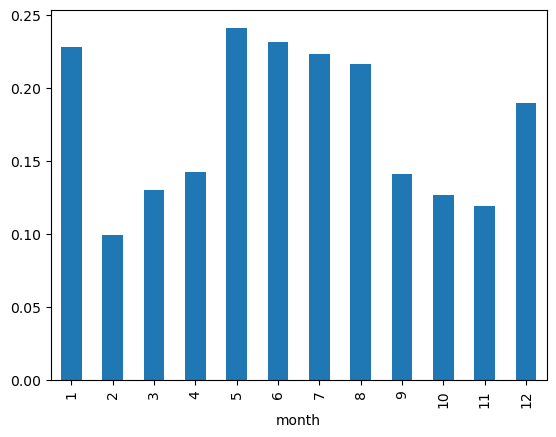

<Axes: xlabel='airline'>

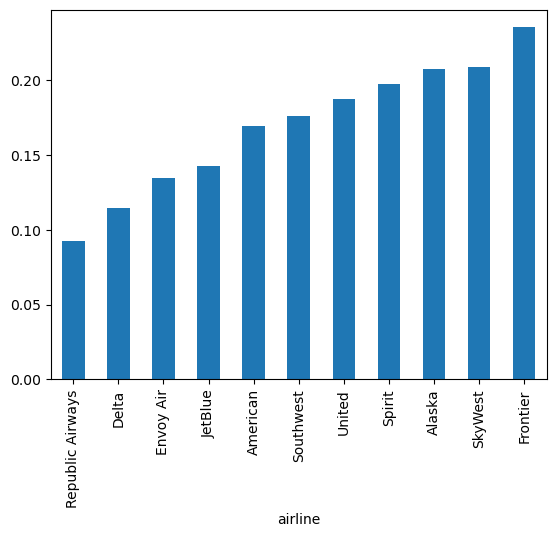

In [6]:
df = merged.copy()

#looks at datetime column, takes hour of each datetime and stores in new column
df["dep_hour"] = df["scheduled_departure"].dt.hour

# copy of dep_hour but replaces 0 rows with 24
df['dep_hour_plot'] = df["dep_hour"].replace({0:24})

#group different dep_hour_plot values and date delayed column, computing mean
hour_delay_rate = df.groupby("dep_hour_plot")["delayed"].mean()

#sort hour_delay_rate by hour and plot
hour_delay_rate.sort_index().plot(kind="bar")
plt.tight_layout
plt.show()
#group values by month and compute mean of delayed time
month_delay_rate = df.groupby("month")["delayed"].mean()

month_delay_rate.sort_index().plot(kind="bar")
plt.tight_layout
plt.show()
#group values by airline and compute mean of delayed time per airline
airline_delay_rate = df.groupby("airline")["delayed"].mean()

airline_delay_rate.sort_values().plot(kind="bar")


In [7]:
#takes delayed column and changes type to int
y = merged["delayed"].astype(int)

num_features = ["month", 
                "day_of_week", 
                "scheduled_duration_min", 
                "temperature_f", 
                "dewpoint_f", 
                "humidity_pct", 
                "wind_direction_deg", 
                "wind_speed_knots", 
                "visibility_miles", 
                "pressure_inhg", 
                "cloud_cover_oktas", 
                "precip_inches",
                "rain", 
                "snow", 
                "thunderstorm"
                ]

#new dataset X made from only selected columns
X = merged[num_features].copy()

#gets hours from scheduled_departure and adds it as new col in X
X["dep_hour"] = merged["scheduled_departure"].dt.hour

#get_dummes creates binary per airline, stores in new df
airline_dummies = pd.get_dummies(merged["airline"], prefix="airline")

X = pd.concat([X, airline_dummies], axis=1)

X.shape

(27348, 27)

In [ ]:
#train/test split with 20% test size, 80% train size
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size = 0.2, random_state=5)

#HisGradientBoostingClassifer gradient boosts with histograms, then fits model to X_train, y_train
hgb_baseline = HistGradientBoostingClassifier(random_state=5)
hgb_baseline.fit(X_train, y_train)

# uses model to predict class labels based on X_test
y_pred_base = hgb_baseline.predict(X_test)

#classification_report compares y_test to y_pred_base, giving test scores on each class
print(classification_report(y_test,y_pred_base,target_names=["on time", "delayed"]))

              precision    recall  f1-score   support

     on time       0.84      0.99      0.91      4538
     delayed       0.58      0.07      0.12       932

    accuracy                           0.83      5470
   macro avg       0.71      0.53      0.52      5470
weighted avg       0.79      0.83      0.77      5470



In [10]:
# balanced model weight, giving minority classes higher weight and majority classes lower weight
hgb_balanced = HistGradientBoostingClassifier (class_weight = "balanced", random_state=5)

hgb_balanced.fit(X_train, y_train)

y_pred_bal = hgb_balanced.predict(X_test)

print(classification_report(y_test,y_pred_bal,target_names=["on time", "delayed"]))

              precision    recall  f1-score   support

     on time       0.90      0.71      0.79      4538
     delayed       0.30      0.60      0.40       932

    accuracy                           0.69      5470
   macro avg       0.60      0.65      0.59      5470
weighted avg       0.79      0.69      0.72      5470



<BarContainer object of 15 artists>

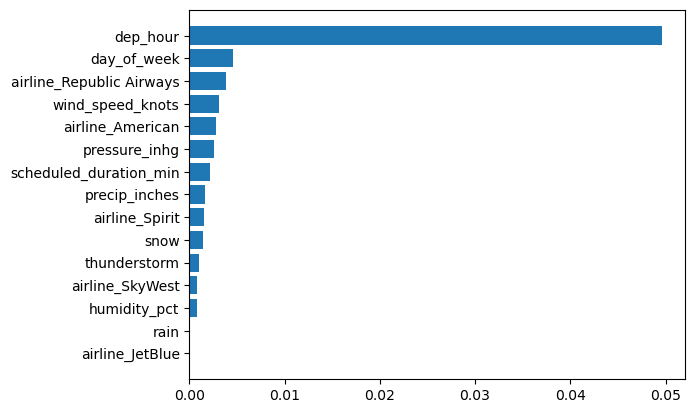

In [11]:
#permutation_importance measures model's test performace drop when shuffling one feature at a time
result = permutation_importance(
    hgb_balanced,
    X_test,
    y_test,
    n_repeats=10,
    random_state=5,
    n_jobs=-1
)

# array contatining mean decrease in accuracy when feature is changed
importance_mean = result.importances_mean
feature_names = np.array(X.columns)

#argsort returns indices sorting importance values from smallest to largest, taking the largest 15
idx = np.argsort(importance_mean)[-15:]
top_features = feature_names[idx]
top_importances = importance_mean[idx]

plt.barh(top_features, top_importances)

/opt/miniconda3/envs/math10/lib/python3.14/site-packages/sklearn/inspection/_partial_dependence.py:721: FutureWarning: The column 15 contains integer data. Partial dependence plots are not supported for integer data: this can lead to implicit rounding with NumPy arrays or even errors with newer pandas versions. Please convert numerical featuresto floating point dtypes ahead of time to avoid problems. This will raise ValueError in scikit-learn 1.9.
  warnings.warn(
/opt/miniconda3/envs/math10/lib/python3.14/site-packages/sklearn/inspection/_partial_dependence.py:721: FutureWarning: The column 0 contains integer data. Partial dependence plots are not supported for integer data: this can lead to implicit rounding with NumPy arrays or even errors with newer pandas versions. Please convert numerical featuresto floating point dtypes ahead of time to avoid problems. This will raise ValueError in scikit-learn 1.9.
  warnings.warn(


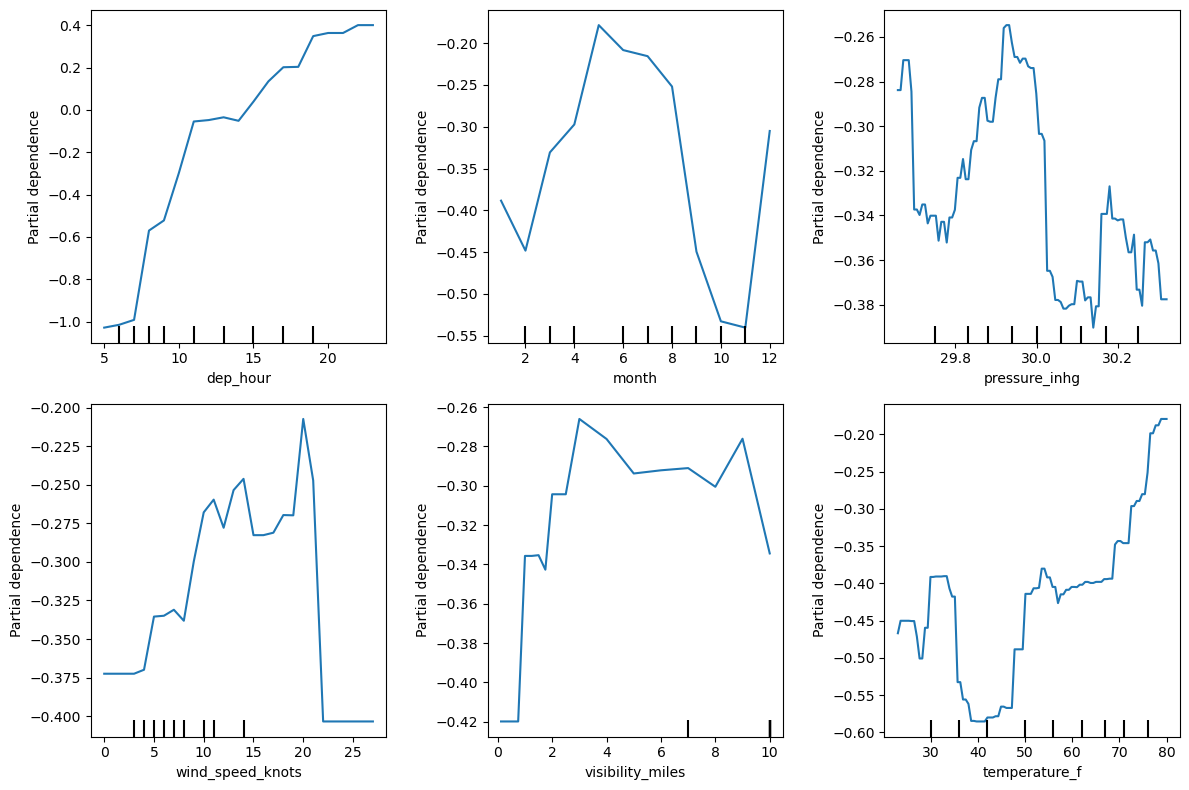

In [12]:
feature_to_plot = [
    "dep_hour",
    "month",
    "pressure_inhg",
    "wind_speed_knots",
    "visibility_miles",
    "temperature_f"
]

fig, axs = plt.subplots(2,3, figsize=(12,8))

for ax, feat in zip(axs.ravel(), feature_to_plot):
    PartialDependenceDisplay.from_estimator(
        hgb_balanced,
        X,
        [feat],
        ax=ax
        )
plt.tight_layout()